# ZOZO ECデータ分析：顧客への配送遅延とレビュー評価

## 分析目的
顧客への配送遅延がレビュー評価とどのように関係するかを確認し、配送工程・販売者・商品カテゴリーの観点から、ZOZOが状況把握や改善の働きかけを検討するための手がかりを探る。

**主分析の遅延定義：** `order_delivered_customer_date > order_estimated_delivery_date`（実際の顧客配達日時が予定配達日時を超えた注文）。

※ `shipping_limit_date` は販売者側の出荷期限であり、顧客への配送遅延とは別の指標。本分析では顧客への配送遅延を主指標とする。

**分析上の立場：** 本分析で抽出する販売者・カテゴリーは、改善対象となる可能性のある候補である。遅延の具体的な原因や有効な対策を特定するには、販売者への確認や追加データによる検証が必要である。

**データの位置づけ：** 使用データはOlistの公開ECデータセットであり、ZOZOの実データではない。ZOZOのようなプラットフォーム運営者の立場を想定したケーススタディとして分析する。

## データセットの採用理由
本分析では、Olistの公開ECデータセットを採用した。このデータセットには、注文日時・配送業者への引き渡し日時・顧客への配達日時・予定配達日時に加え、レビュー評価、販売者ID、商品カテゴリーなどが含まれている。そのため、**配送工程ごとの所要日数と顧客への配送遅延の関係を確認し、さらにレビュー評価や販売者・商品カテゴリー別の傾向を関連づけて分析できる**と考えた。また、複数の販売者が商品を販売するECの注文データであるため、プラットフォーム運営者が販売者ごとの状況を把握し、改善候補を検討するという今回の分析テーマにも適している。

一方で、OlistはZOZOとは異なる事業者・サービスであり、データもZOZOの実際の運営状況を表すものではない。したがって、ZOZOの実態を直接評価するのではなく、ECプラットフォームにおける配送課題を分析するためのケーススタディとして用いる。


## 1. 分析の流れと分析単位

1. CSV読み込み・日付型変換
2. 注文単位で顧客配送遅延とレビュー評価を比較
3. 配送工程を分けて所要日数と顧客配送遅延の関係を確認
   - 注文→配送業者への引き渡し（引き渡し前工程）
   - 配送業者への引き渡し→顧客配達（輸送工程）
4. 販売者別・カテゴリー別・販売者×カテゴリー別に顧客配送遅延率を比較
5. 結果を踏まえ、ZOZOの立場から改善候補と追加調査の方向性を考察

**分析単位：** 顧客配送遅延とレビューは注文単位。販売者・カテゴリー分析は注文×販売者、または注文×販売者×カテゴリー単位で重複を整理して集計する。


## 2. ライブラリ・データ読み込み

Google Drive内の保存先が異なる場合は `DATA_DIR` を変更してください。


In [ ]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Google ColabではGoogle Driveを利用し、それ以外の環境ではローカルのCSVフォルダを利用する
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/ZOZO_DataAnalysis/data'
except ModuleNotFoundError:
    DATA_DIR = '/mnt/data/olist_data'

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
# 日本語フォントが利用可能な環境ではグラフの日本語ラベルに適用する
import matplotlib.font_manager as fm
font_names = {font.name for font in fm.fontManager.ttflist}
if 'Noto Sans CJK JP' in font_names:
    plt.rcParams['font.family'] = 'Noto Sans CJK JP'
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'

orders = pd.read_csv(os.path.join(DATA_DIR, 'olist_orders_dataset.csv'))
reviews = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_reviews_dataset.csv'))
order_items = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_items_dataset.csv'))
products = pd.read_csv(os.path.join(DATA_DIR, 'olist_products_dataset.csv'))
category_translation = pd.read_csv(os.path.join(DATA_DIR, 'product_category_name_translation.csv'))

print('データ保存先:', DATA_DIR)
print('orders:', orders.shape)
print('reviews:', reviews.shape)
print('order_items:', order_items.shape)
print('products:', products.shape)
print('category_translation:', category_translation.shape)


データ保存先: /mnt/data/olist_data
orders: (99441, 8)
reviews: (99224, 7)
order_items: (112650, 7)
products: (32951, 9)
category_translation: (71, 2)


## 3. 前処理と注文単位の分析データ
同一注文に複数レビューがある場合は平均評価を代表値とする。配達完了済みで、実際・予定の配達日時とレビュー評価が確認できる注文を対象とする。

In [ ]:
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews_order = (reviews.groupby('order_id', as_index=False)
                 .agg(review_score=('review_score', 'mean')))

analysis_df = orders.loc[
    (orders['order_status'] == 'delivered') &
    orders['order_delivered_customer_date'].notna() &
    orders['order_estimated_delivery_date'].notna()
].merge(reviews_order, on='order_id', how='inner')

analysis_df = analysis_df.dropna(subset=['review_score']).copy()
analysis_df['delay_days'] = (
    analysis_df['order_delivered_customer_date'] -
    analysis_df['order_estimated_delivery_date']
).dt.total_seconds() / 86400
analysis_df['is_late'] = analysis_df['delay_days'] > 0

print('分析対象注文数:', analysis_df['order_id'].nunique())
print('注文ID重複数:', analysis_df['order_id'].duplicated().sum())
print(f"顧客への配送遅延率: {analysis_df['is_late'].mean()*100:.2f}%")
display(analysis_df[['delay_days','review_score']].describe().round(2))

分析対象注文数: 95824
注文ID重複数: 0
顧客への配送遅延率: 7.99%


,delay_days,review_score
count,95824.00,95824.00
mean,-11.22,4.16
std,10.11,1.28
min,-146.02,1.00
25%,-16.25,4.00
50%,-11.97,5.00
75%,-6.41,5.00
max,188.98,5.00


## 4. 顧客への配送遅延とレビュー評価
まず、予定日以内に届いた注文と予定日を超過した注文で、平均レビュー評価・低評価率を比較する。低評価はレビュー1または2と定義する。

,order_count,average_review,median_review,low_review_rate_pct
予定日以内,88163,4.294,5.0,9.188
予定日超過,7661,2.567,2.0,53.988


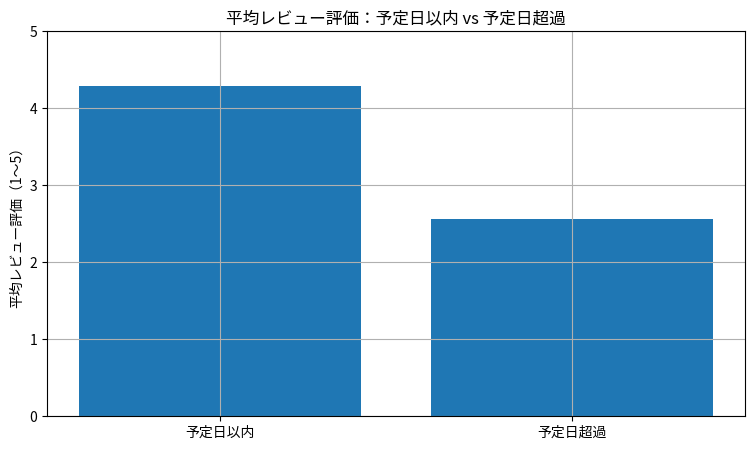

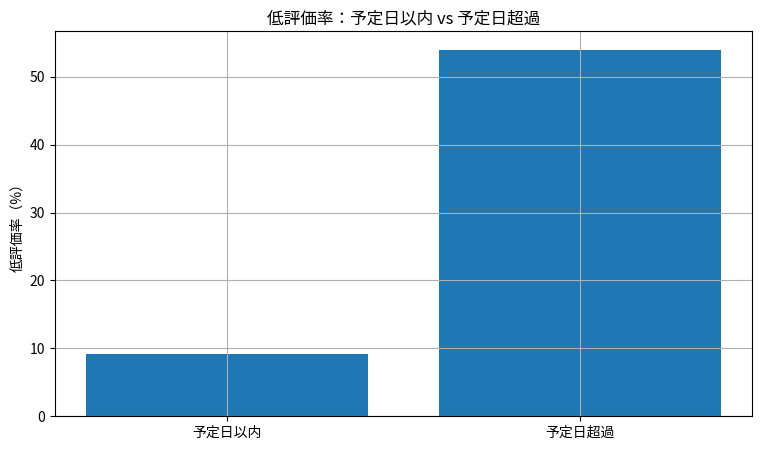

In [ ]:
analysis_df['low_review'] = analysis_df['review_score'] <= 2
review_summary = (analysis_df.groupby('is_late')
    .agg(order_count=('order_id','nunique'),
         average_review=('review_score','mean'),
         median_review=('review_score','median'),
         low_review_rate=('low_review','mean')))
review_summary.index = ['予定日以内','予定日超過']
review_summary['low_review_rate_pct'] = review_summary.pop('low_review_rate') * 100
display(review_summary.round(3))

fig, ax = plt.subplots()
ax.bar(review_summary.index, review_summary['average_review'])
ax.set_title('平均レビュー評価：予定日以内 vs 予定日超過')
ax.set_ylabel('平均レビュー評価（1〜5）')
ax.set_ylim(0,5)
plt.show()

fig, ax = plt.subplots()
ax.bar(review_summary.index, review_summary['low_review_rate_pct'])
ax.set_title('低評価率：予定日以内 vs 予定日超過')
ax.set_ylabel('低評価率（%）')
plt.show()

### 4-1. 遅延日数別のレビュー評価
遅延日数を1日刻み（長い遅延はまとめる）に区分し、平均レビュー評価と低評価率を比較する。低評価は、注文単位の代表値である平均レビューが2以下と定義する。予定日以内の注文も比較基準として表示する。

この分析では、遅延を許容する日数を決めるのではなく、**遅延が発生した場合に、何日以上の長期化を避けるべきか**を検討する。

,order_count,average_review,low_review_rate_pct
予定日以内,88163,4.29,9.19
1日以内,1280,4.04,12.27
1〜2日,820,3.73,19.76
2〜3日,536,3.18,34.33
3〜4日,496,2.68,50.40
4〜5日,436,2.50,55.96
5〜6日,434,2.19,64.52
6〜7日,407,1.81,76.66
7〜10日,1020,1.80,76.57
10〜14日,728,1.67,80.08


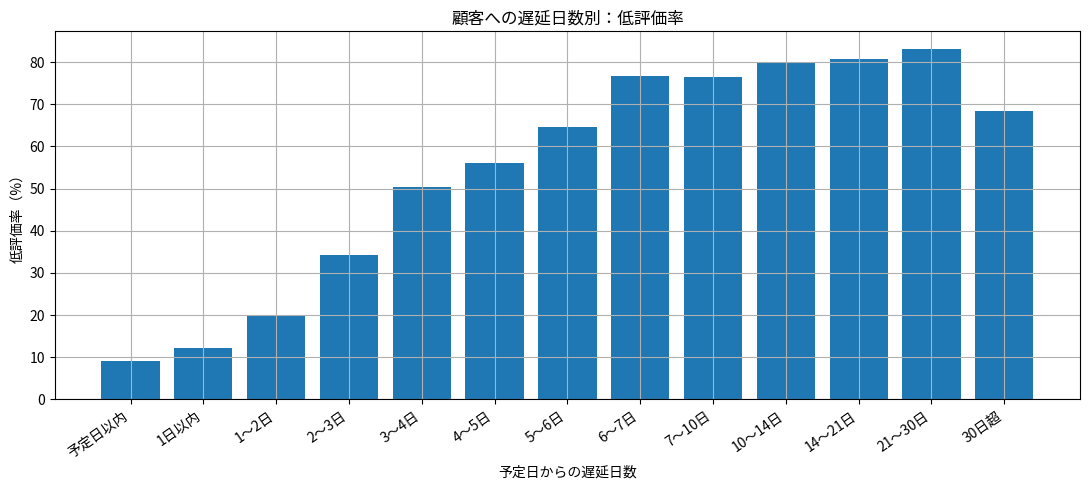

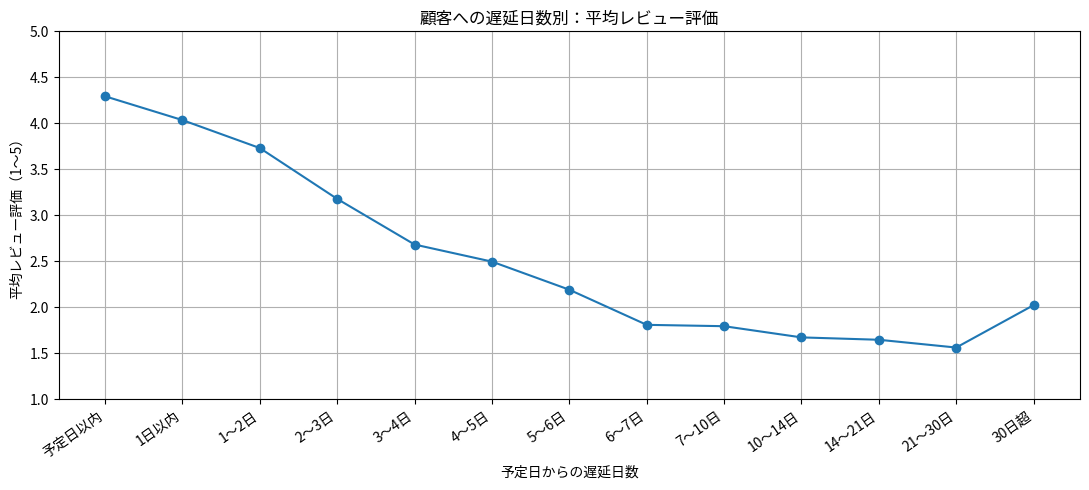

In [ ]:
# 遅延日数は小数（日）で計算されているため、0日超〜1日以内、1日超〜2日以内…として区分する
late_only = analysis_df.loc[analysis_df['delay_days'] > 0].copy()
bins = [0, 1, 2, 3, 4, 5, 6, 7, 10, 14, 21, 30, np.inf]
labels = ['1日以内', '1〜2日', '2〜3日', '3〜4日', '4〜5日', '5〜6日',
          '6〜7日', '7〜10日', '10〜14日', '14〜21日', '21〜30日', '30日超']
late_only['delay_group'] = pd.cut(late_only['delay_days'], bins=bins, labels=labels, right=True)
late_summary = (late_only.groupby('delay_group', observed=False)
    .agg(order_count=('order_id', 'nunique'),
         average_review=('review_score', 'mean'),
         low_review_rate=('low_review', 'mean')))
late_summary['low_review_rate_pct'] = late_summary.pop('low_review_rate') * 100

# 予定日以内を基準行として追加
on_time_row = pd.DataFrame({
    'order_count': [analysis_df.loc[~analysis_df['is_late'], 'order_id'].nunique()],
    'average_review': [analysis_df.loc[~analysis_df['is_late'], 'review_score'].mean()],
    'low_review_rate_pct': [analysis_df.loc[~analysis_df['is_late'], 'low_review'].mean() * 100]
}, index=['予定日以内'])
delay_review_summary = pd.concat([on_time_row, late_summary[['order_count', 'average_review', 'low_review_rate_pct']]])
display(delay_review_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(delay_review_summary.index.astype(str), delay_review_summary['low_review_rate_pct'])
ax.set_title('顧客への遅延日数別：低評価率')
ax.set_xlabel('予定日からの遅延日数')
ax.set_ylabel('低評価率（%）')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(delay_review_summary.index.astype(str), delay_review_summary['average_review'], marker='o')
ax.set_title('顧客への遅延日数別：平均レビュー評価')
ax.set_xlabel('予定日からの遅延日数')
ax.set_ylabel('平均レビュー評価（1〜5）')
ax.set_ylim(1, 5)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

### 4-2. 低評価率の悪化を抑えるための遅延日数の目安
1日刻みの結果を踏まえ、遅延した注文を「遅延2日以内」と「遅延2日超」に分け、低評価率を比較する。ここでの2日という区切りは、今回のデータで低評価率の上昇が大きくなる箇所を運用上の対応目標として検討するためのものであり、遅延を許容する基準ではない。


,order_count,average_review,low_review_rate_pct
予定日以内,88163,4.29,9.19
遅延2日以内,2100,3.92,15.19
遅延2日超,5561,2.06,68.64


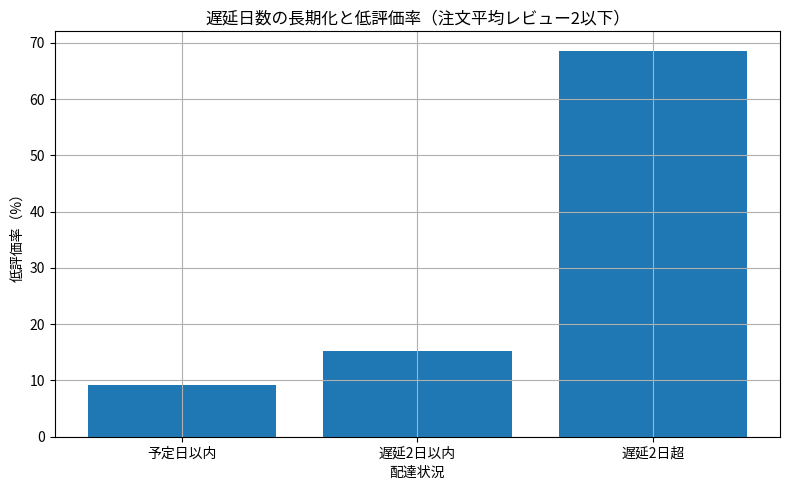

低評価率の差（2日超 − 2日以内）: 53.45ポイント
低評価率の比（2日超 ÷ 2日以内）: 4.52倍


In [ ]:
# 遅延が発生した注文を、2日以内に配達された群と2日を超えて遅延した群に分ける
late_only = analysis_df.loc[analysis_df['delay_days'] > 0].copy()
late_only['delay_recovery_group'] = np.where(
    late_only['delay_days'] <= 2, '遅延2日以内', '遅延2日超'
)
threshold_summary = (late_only.groupby('delay_recovery_group')
    .agg(order_count=('order_id', 'nunique'),
         average_review=('review_score', 'mean'),
         low_review_rate=('low_review', 'mean')))
threshold_summary['low_review_rate_pct'] = threshold_summary.pop('low_review_rate') * 100

# 予定日以内の注文を比較基準として追加
baseline = pd.DataFrame({
    'order_count': [analysis_df.loc[~analysis_df['is_late'], 'order_id'].nunique()],
    'average_review': [analysis_df.loc[~analysis_df['is_late'], 'review_score'].mean()],
    'low_review_rate_pct': [analysis_df.loc[~analysis_df['is_late'], 'low_review'].mean() * 100]
}, index=['予定日以内'])
threshold_summary = pd.concat([baseline, threshold_summary[['order_count', 'average_review', 'low_review_rate_pct']]])
display(threshold_summary.round(2))

# 低評価率の比較を可視化
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(threshold_summary.index.astype(str), threshold_summary['low_review_rate_pct'])
ax.set_title('遅延日数の長期化と低評価率（注文平均レビュー2以下）')
ax.set_ylabel('低評価率（%）')
ax.set_xlabel('配達状況')
plt.tight_layout()
plt.show()

# 2日以内と2日超の差を数値で確認
short_rate = threshold_summary.loc['遅延2日以内', 'low_review_rate_pct']
long_rate = threshold_summary.loc['遅延2日超', 'low_review_rate_pct']
print(f'低評価率の差（2日超 − 2日以内）: {long_rate - short_rate:.2f}ポイント')
print(f'低評価率の比（2日超 ÷ 2日以内）: {long_rate / short_rate:.2f}倍')


## 5. 配送工程別の所要時間

配送工程を次の2つに分けて所要日数を計算する。
- 注文→配送業者への引き渡し：販売者側の出荷準備・引き渡しに関係する工程
- 配送業者への引き渡し→顧客配達：引き渡し後の輸送工程

あわせて、注文→顧客配達までの全体所要時間も確認する。工程ごとの日数と顧客配送遅延の関係は関連として捉え、原因を断定しない。


purchase_to_delivery_days         ... carrier_to_customer_days       
                          count   mean  ...                     mean median
予定日以内                     88163  10.88  ...                     7.89   6.92
予定日超過                      7661  31.38  ...                    25.56  23.87

[2 rows x 9 columns]

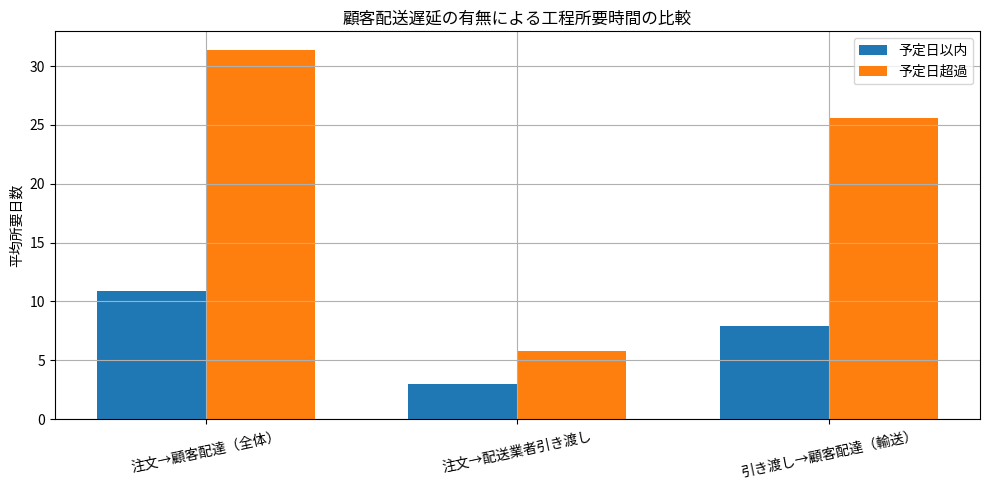

In [ ]:
delivery_df = analysis_df.copy()
delivery_df['purchase_to_delivery_days'] = (
    delivery_df['order_delivered_customer_date'] - delivery_df['order_purchase_timestamp']
).dt.total_seconds()/86400
delivery_df['purchase_to_carrier_days'] = (
    delivery_df['order_delivered_carrier_date'] - delivery_df['order_purchase_timestamp']
).dt.total_seconds()/86400
delivery_df['carrier_to_customer_days'] = (
    delivery_df['order_delivered_customer_date'] - delivery_df['order_delivered_carrier_date']
).dt.total_seconds()/86400

stage_cols = ['purchase_to_delivery_days','purchase_to_carrier_days','carrier_to_customer_days']
valid_stage = delivery_df.copy()
for col in stage_cols:
    valid_stage.loc[valid_stage[col] < 0, col] = np.nan

stage_summary = valid_stage.groupby('is_late')[stage_cols].agg(['count','mean','median'])
stage_summary.index = ['予定日以内','予定日超過']
display(stage_summary.round(2))

stage_labels = {
    'purchase_to_delivery_days':'注文→顧客配達（全体）',
    'purchase_to_carrier_days':'注文→配送業者引き渡し',
    'carrier_to_customer_days':'引き渡し→顧客配達（輸送）'
}
plot_data = valid_stage.groupby('is_late')[stage_cols].mean().T
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(stage_cols)); width = 0.35
ax.bar(x-width/2, plot_data[False].values, width, label='予定日以内')
ax.bar(x+width/2, plot_data[True].values, width, label='予定日超過')
ax.set_xticks(x); ax.set_xticklabels([stage_labels[k] for k in stage_cols], rotation=12)
ax.set_ylabel('平均所要日数'); ax.set_title('顧客配送遅延の有無による工程所要時間の比較')
ax.legend(); plt.tight_layout(); plt.show()

### 5-1. 引き渡し前工程の日数と顧客配送遅延率
注文から配送業者への引き渡しまでの日数を区分し、各区分の顧客配送遅延率を比較する。区分は「1日以内」「1日超〜2日以内」「2日超〜3日以内」「3日超」とする。これは関連の確認であり、引き渡し前工程が遅延の原因だと断定するものではない。

,order_count,late_rate_pct
pre_carrier_group,,
1日以内,18877,3.98
1日超〜2日以内,23857,5.86
2日超〜3日以内,16185,7.16
3日超,36740,11.83


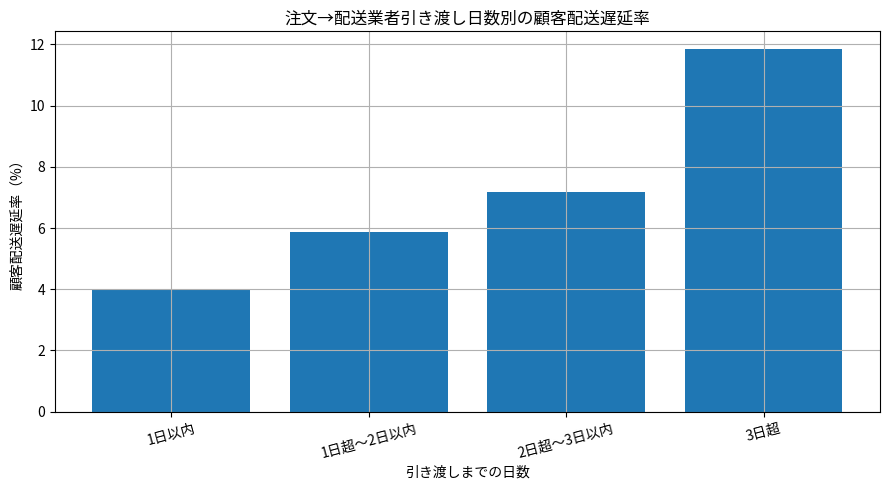

In [ ]:
pre = valid_stage.dropna(subset=['purchase_to_carrier_days']).copy()
pre = pre[pre['purchase_to_carrier_days'] >= 0]
pre['pre_carrier_group'] = pd.cut(
    pre['purchase_to_carrier_days'],
    bins=[-0.001, 1, 2, 3, np.inf],
    labels=['1日以内', '1日超〜2日以内', '2日超〜3日以内', '3日超'],
    include_lowest=True
)
pre_summary = pre.groupby('pre_carrier_group', observed=False).agg(
    order_count=('order_id','nunique'), late_rate=('is_late','mean'))
pre_summary['late_rate_pct'] = pre_summary.pop('late_rate')*100
display(pre_summary.round(2))
fig, ax = plt.subplots()
ax.bar(pre_summary.index.astype(str), pre_summary['late_rate_pct'])
ax.set_title('注文→配送業者引き渡し日数別の顧客配送遅延率')
ax.set_ylabel('顧客配送遅延率（%）'); ax.set_xlabel('引き渡しまでの日数')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 5-2. 輸送工程の日数と顧客配送遅延率
配送業者への引き渡しから顧客への配達までの日数を区分し、顧客配送遅延率を比較する。輸送工程は主に配送業者が担うため、ここでは工程全体の傾向を把握するにとどめ、販売者ごとの輸送日数比較は行わない。

,order_count,late_rate_pct
transport_group,,
3日以内,15995,2.39
3〜6日,21143,1.74
6〜9日,23164,1.64
9〜12日,11458,2.60
12日超,24040,25.93


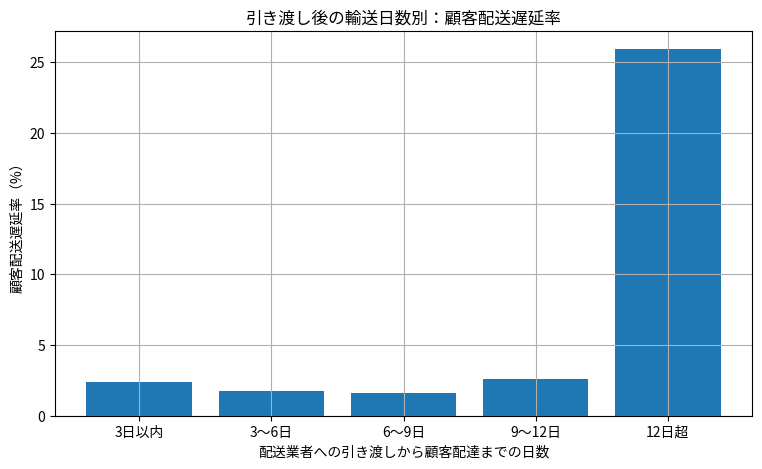

In [ ]:
trans = valid_stage.dropna(subset=['carrier_to_customer_days']).copy()
trans = trans[trans['carrier_to_customer_days'] >= 0]
trans['transport_group'] = pd.cut(
    trans['carrier_to_customer_days'],
    bins=[-0.001, 3, 6, 9, 12, np.inf],
    labels=['3日以内', '3〜6日', '6〜9日', '9〜12日', '12日超'],
    include_lowest=True
)
transport_summary = trans.groupby('transport_group', observed=False).agg(
    order_count=('order_id', 'nunique'),
    late_rate=('is_late', 'mean')
)
transport_summary['late_rate_pct'] = transport_summary.pop('late_rate') * 100
display(transport_summary.round(2))

fig, ax = plt.subplots()
ax.bar(transport_summary.index.astype(str), transport_summary['late_rate_pct'])
ax.set_title('引き渡し後の輸送日数別：顧客配送遅延率')
ax.set_xlabel('配送業者への引き渡しから顧客配達までの日数')
ax.set_ylabel('顧客配送遅延率（%）')
plt.show()


## 6. 販売者別の顧客配送遅延率
販売者ごとの違いを見る。ただし1つの注文に複数販売者の商品が含まれることがあるため、注文×販売者を1行として扱う。同じ販売者の商品が同じ注文に複数あっても重複カウントしない。

対象販売者数（注文30件以上）: 623


,seller_id,order_count,late_rate,average_review,late_rate_pct
2761,ede0c03645598cdfc63ca8237acbe73d,42,0.333,3.571,33.333
2007,ad781527c93d00d89a11eecd9dcad7c1,38,0.316,3.342,31.579
1553,835f0f7810c76831d6c7d24c7a646d4d,42,0.310,3.357,30.952
998,54965bbe3e4f07ae045b90b0b8541f52,69,0.290,3.145,28.986
1207,66e0557ecc2b4dbea057e93f215f68d8,30,0.267,4.033,26.667
1924,a49928bcdf77c55c6d6e05e09a9b4ca5,96,0.260,3.031,26.042
2776,ef990a83bbea832f36ebe81376335aa8,43,0.256,3.628,25.581
477,2a1348e9addc1af5aaa619b1a3679d6b,47,0.255,3.170,25.532
2206,beadbee30901a7f61d031b6b686095ad,64,0.250,3.906,25.000
1331,71039d19d4303bf9054d69e9a9236699,35,0.229,3.800,22.857


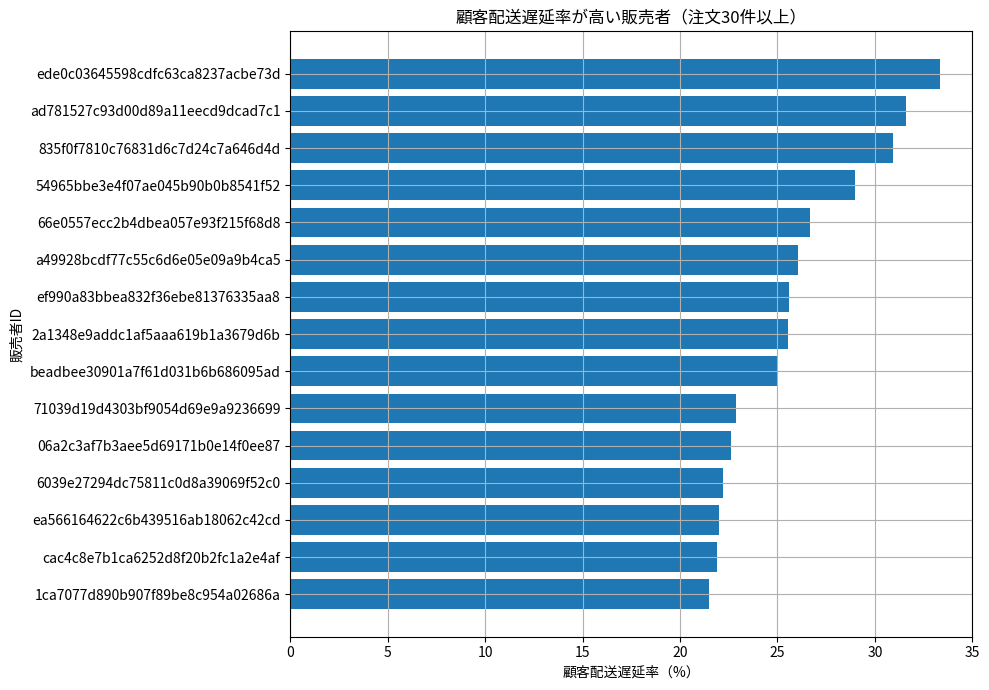

In [ ]:
seller_orders = (order_items[['order_id','seller_id']].drop_duplicates()
    .merge(analysis_df[['order_id','is_late','review_score']], on='order_id', how='inner'))
seller_summary = seller_orders.groupby('seller_id').agg(
    order_count=('order_id','nunique'),
    late_rate=('is_late','mean'),
    average_review=('review_score','mean')).reset_index()
seller_summary['late_rate_pct'] = seller_summary['late_rate']*100
seller_30 = seller_summary[seller_summary['order_count'] >= 30].copy()
print('対象販売者数（注文30件以上）:', len(seller_30))
display(seller_30.sort_values('late_rate_pct',ascending=False).head(15).round(3))

seller_top = seller_30.nlargest(15,'late_rate_pct').sort_values('late_rate_pct')
fig, ax = plt.subplots(figsize=(10,7))
ax.barh(seller_top['seller_id'].astype(str), seller_top['late_rate_pct'])
ax.set_title('顧客配送遅延率が高い販売者（注文30件以上）')
ax.set_xlabel('顧客配送遅延率（%）'); ax.set_ylabel('販売者ID')
plt.tight_layout(); plt.show()

## 7. 商品カテゴリー別の顧客配送遅延率
商品明細に注文単位の遅延フラグを結合する。カテゴリー別の集計では、同じ注文に同じカテゴリーの商品が複数含まれていても1注文として数える。これにより、注文数と遅延率の分母をそろえる。

対象カテゴリー数（注文30件以上）: 63


,category_label,order_count,late_rate_pct,average_review
52,furniture_mattress_and_upholstery,37,13.514,3.892
39,fashion_underwear_beach,116,12.931,4.009
7,audio,345,12.754,3.839
49,books_technical,255,10.980,4.427
14,home_confort,390,10.513,3.887
1,food,437,9.840,4.327
30,electronics,2498,9.808,4.124
23,construction_tools_lights,239,9.205,4.151
9,baby,2787,9.006,4.104
55,office_furniture,1244,9.003,3.643


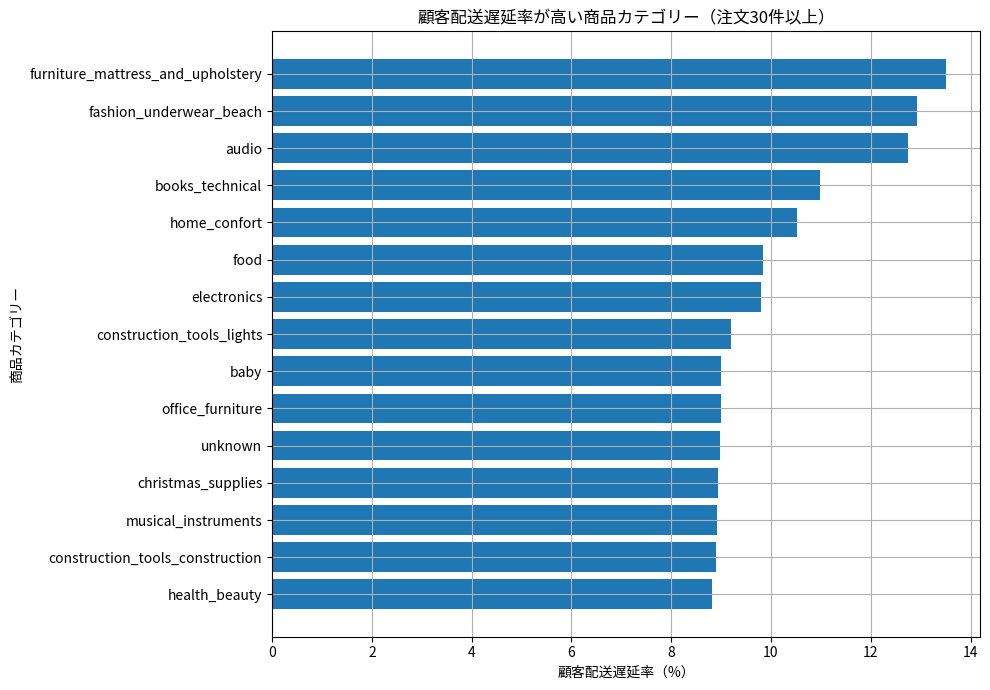

In [ ]:
item_category = (order_items[['order_id','seller_id','product_id']]
    .merge(products[['product_id','product_category_name']], on='product_id', how='left')
    .merge(analysis_df[['order_id','is_late','review_score']], on='order_id', how='inner'))

# カテゴリー別は注文×カテゴリーで重複を除き、注文数と遅延率の単位を一致させる
item_category_order = item_category.drop_duplicates(['order_id','product_category_name']).copy()
category_summary = item_category_order.groupby('product_category_name', dropna=False).agg(
    order_count=('order_id','nunique'),
    late_rate=('is_late','mean'),
    average_review=('review_score','mean')).reset_index()
category_summary['late_rate_pct'] = category_summary['late_rate']*100
category_summary = category_summary.merge(category_translation, on='product_category_name', how='left')
category_summary['category_label'] = category_summary['product_category_name_english'].fillna(category_summary['product_category_name']).fillna('unknown')
category_30 = category_summary[category_summary['order_count'] >= 30].copy()
print('対象カテゴリー数（注文30件以上）:', len(category_30))
display(category_30.sort_values('late_rate_pct',ascending=False)[['category_label','order_count','late_rate_pct','average_review']].head(15).round(3))
category_top = category_30.nlargest(15,'late_rate_pct').sort_values('late_rate_pct')
fig, ax = plt.subplots(figsize=(10,7))
ax.barh(category_top['category_label'].astype(str), category_top['late_rate_pct'])
ax.set_title('顧客配送遅延率が高い商品カテゴリー（注文30件以上）')
ax.set_xlabel('顧客配送遅延率（%）'); ax.set_ylabel('商品カテゴリー')
plt.tight_layout(); plt.show()

## 8. 販売者×商品カテゴリー別の顧客配送遅延率
ここでいう1つの「組み合わせ」は、**特定の販売者が特定の商品カテゴリーの商品を販売した注文群**を指す。たとえば「販売者A × 家具カテゴリー」の注文群をひとまとまりとして、その注文数と顧客配送遅延率を計算する。

これは「販売者全体で遅延率が高いか」だけでなく、「その販売者のどのカテゴリーで遅延率が高いか」を見つけるための分析。30注文以上ある組み合わせに絞るが、この件数条件は極端に少ないデータを避けるための目安であり、統計的な保証ではない。

**表の見方：** 注文数＝その販売者×カテゴリーの注文数、遅延注文数＝予定日を超えて届いた注文数、遅延率＝遅延注文数÷注文数。高い遅延率だけでなく注文数も併せて判断する。

全組み合わせ数: 6374
30注文以上の組み合わせ数: 625
顧客配送遅延率の高い組み合わせ（上位10件）


,seller_id,product_category_name,order_count,late_orders,late_rate_pct,average_review
3361,835f0f7810c76831d6c7d24c7a646d4d,utilidades_domesticas,34,11,32.353,3.559
4338,ad781527c93d00d89a11eecd9dcad7c1,bebes,38,12,31.579,3.342
5902,ede0c03645598cdfc63ca8237acbe73d,informatica_acessorios,36,11,30.556,3.667
3491,891071be6ba827b591264c90c2ae8a63,fashion_bolsas_e_acessorios,40,12,30.000,3.625
2148,54965bbe3e4f07ae045b90b0b8541f52,cama_mesa_banho,69,20,28.986,3.145
2448,6039e27294dc75811c0d8a39069f52c0,eletronicos,35,10,28.571,3.800
5930,ef990a83bbea832f36ebe81376335aa8,esporte_lazer,39,11,28.205,3.564
2580,66e0557ecc2b4dbea057e93f215f68d8,consoles_games,30,8,26.667,4.033
4885,c60b801f2d52c7f7f91de00870882a75,relogios_presentes,30,8,26.667,3.367
4190,a49928bcdf77c55c6d6e05e09a9b4ca5,brinquedos,82,21,25.610,2.976


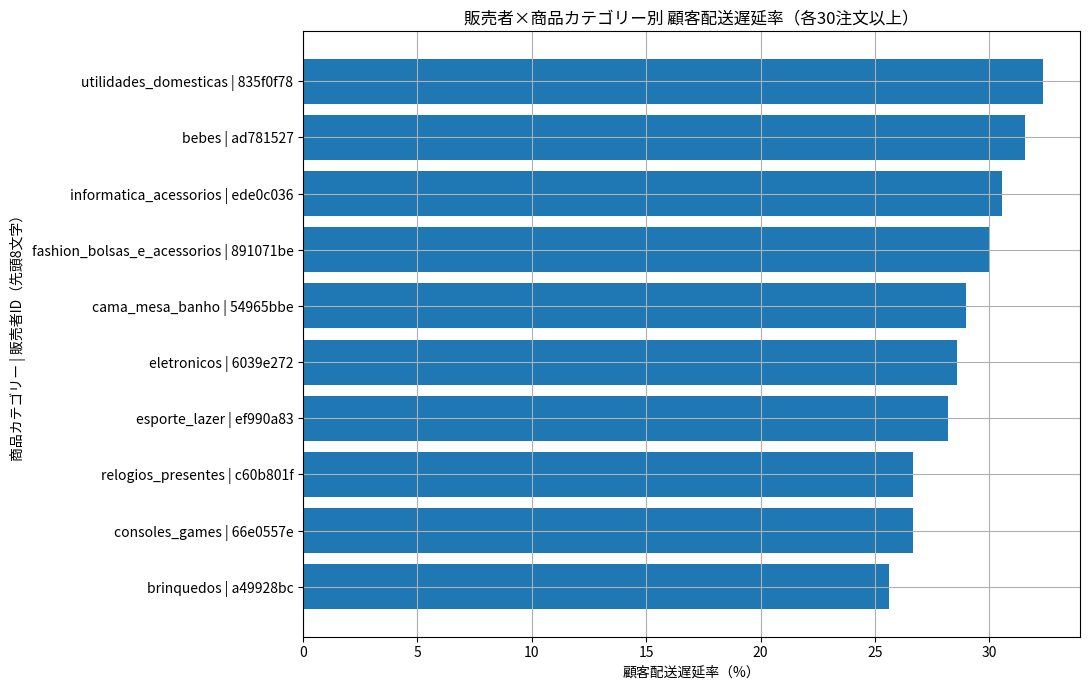

In [ ]:
seller_category_rows = item_category.drop_duplicates(
    ['order_id','seller_id','product_category_name']).copy()
seller_category_summary = seller_category_rows.groupby(
    ['seller_id','product_category_name'], dropna=False).agg(
        order_count=('order_id','nunique'),
        late_orders=('is_late','sum'),
        late_rate=('is_late','mean'),
        average_review=('review_score','mean')).reset_index()
seller_category_summary['late_rate_pct'] = seller_category_summary['late_rate']*100
seller_category_30 = seller_category_summary[
    seller_category_summary['order_count'] >= 30].copy()

candidates = seller_category_30.sort_values(
    ['late_rate_pct','order_count'], ascending=[False,False])
print('全組み合わせ数:', len(seller_category_summary))
print('30注文以上の組み合わせ数:', len(seller_category_30))
print('顧客配送遅延率の高い組み合わせ（上位10件）')
display(candidates[['seller_id','product_category_name','order_count',
                    'late_orders','late_rate_pct','average_review']].head(10).round(3))

plot_candidates = candidates.head(10).copy()
plot_candidates['label'] = (plot_candidates['product_category_name'].fillna('不明').astype(str)
                             + ' | ' + plot_candidates['seller_id'].astype(str).str[:8])
plot_candidates = plot_candidates.sort_values('late_rate_pct')
fig, ax = plt.subplots(figsize=(11,7))
ax.barh(plot_candidates['label'], plot_candidates['late_rate_pct'])
ax.set_title('販売者×商品カテゴリー別 顧客配送遅延率（各30注文以上）')
ax.set_xlabel('顧客配送遅延率（%）'); ax.set_ylabel('商品カテゴリー | 販売者ID（先頭8文字）')
plt.tight_layout(); plt.show()

## 9. 結果を踏まえた考察
以下では、各分析の結果を示したうえで、読み取れること、考えられる要因、ZOZOの立場から検討できる具体策を整理する。観察データから原因を断定しない。

In [ ]:
# 注文単位のレビュー差
on_time_review = analysis_df.loc[~analysis_df['is_late'], 'review_score'].mean()
late_review = analysis_df.loc[analysis_df['is_late'], 'review_score'].mean()
on_time_low = analysis_df.loc[~analysis_df['is_late'], 'low_review'].mean()*100
late_low = analysis_df.loc[analysis_df['is_late'], 'low_review'].mean()*100
print('【顧客配送遅延とレビュー】')
print(f'分析対象注文数: {analysis_df.order_id.nunique():,}件')
print(f'予定日以内: 平均レビュー {on_time_review:.3f} / 低評価率 {on_time_low:.2f}%')
print(f'予定日超過: 平均レビュー {late_review:.3f} / 低評価率 {late_low:.2f}%')
print(f'平均評価の差（予定日以内−超過）: {on_time_review-late_review:.3f}')

print('\n【配送工程】')
for col, label in stage_labels.items():
    means = valid_stage.groupby('is_late')[col].mean()
    print(f'{label}: 予定日以内 {means.get(False, np.nan):.2f}日 / 予定日超過 {means.get(True, np.nan):.2f}日')

print('\n【引き渡し前工程の日数別・顧客配送遅延率】')
display(pre_summary.round(2))
print('\n【輸送工程の日数別・顧客配送遅延率】')
display(transport_summary.round(2))

print('\n【販売者×カテゴリー】')
if len(candidates):
    first = candidates.iloc[0]
    print(f"最も遅延率が高い上位候補: 販売者 {first['seller_id']} × カテゴリー {first['product_category_name']}")
    print(f"注文数 {int(first['order_count'])}件、遅延注文 {int(first['late_orders'])}件、遅延率 {first['late_rate_pct']:.2f}%")
else:
    print('30注文以上の組み合わせがありません。')

【顧客配送遅延とレビュー】
分析対象注文数: 95,824件
予定日以内: 平均レビュー 4.294 / 低評価率 9.19%
予定日超過: 平均レビュー 2.567 / 低評価率 53.99%
平均評価の差（予定日以内−超過）: 1.728

【配送工程】
注文→顧客配達（全体）: 予定日以内 10.88日 / 予定日超過 31.38日
注文→配送業者引き渡し: 予定日以内 3.00日 / 予定日超過 5.82日
引き渡し→顧客配達（輸送）: 予定日以内 7.89日 / 予定日超過 25.56日

【引き渡し前工程の日数別・顧客配送遅延率】


,order_count,late_rate_pct
pre_carrier_group,,
1日以内,18877,3.98
1日超〜2日以内,23857,5.86
2日超〜3日以内,16185,7.16
3日超,36740,11.83



【輸送工程の日数別・顧客配送遅延率】


,order_count,late_rate_pct
transport_group,,
3日以内,15995,2.39
3〜6日,21143,1.74
6〜9日,23164,1.64
9〜12日,11458,2.60
12日超,24040,25.93



【販売者×カテゴリー】
最も遅延率が高い上位候補: 販売者 835f0f7810c76831d6c7d24c7a646d4d × カテゴリー utilidades_domesticas
注文数 34件、遅延注文 11件、遅延率 32.35%


### 9-1. 顧客配送遅延とレビュー評価
**分析結果：** 予定日以内に届いた88,163件の平均レビューは4.29、低評価率は9.19%だった。一方、予定日を超過した7,661件では平均レビューが2.57、低評価率が53.99%だった。平均レビューには約1.73点の差があり、低評価率にも大きな差が見られた。

**考察：** 予定日を超過した注文では、予定日以内の注文に比べて平均レビューが低く、低評価率が高かった。この結果から、顧客の評価には商品そのものの品質や価格だけでなく、商品が予定どおり届くかという配送体験も関係している可能性がある。商品に問題がなくても、到着が予定より遅れることで顧客の期待を損ない、評価が下がるケースが考えられる。ただし、レビューには商品品質・価格・問い合わせ対応なども影響するため、配送遅延だけが評価低下の原因とは断定できない。

### 9-2. 遅延日数と低評価率：対応を強化すべき日数の目安
**分析結果：** 予定日以内の注文の低評価率は9.19%だった。遅延が1日以内の注文では12.27%、1〜2日では19.76%、2〜3日では34.33%、3〜4日では50.40%だった。さらに、遅延した注文を2日以内と2日超に分けると、2日以内の2,100件では平均レビュー3.92・低評価率15.19%、2日超の5,561件では平均レビュー2.06・低評価率68.64%だった。2日超の群の低評価率は、2日以内の群より53.45ポイント高く、約4.52倍だった。

**考察：** 遅延が2日以内の群でも、予定日以内の群より低評価率は高く、遅延を完全に防げなかった場合の影響は既に表れている。一方で、遅延が2日を超えた群では低評価率が大きく上昇している。この結果から、**遅延が発生した注文については、3日目に入る前（予定日から2日以内）に配達を完了させることを、顧客評価の大幅な悪化を避けるための優先的なリカバリー目標として設定する**ことが考えられる。

これは「2日間の遅延を許容する」という意味ではない。予定日を超過した時点で顧客への状況通知や販売者・配送状況の確認を開始し、特に48時間を超えそうな注文を優先して対応するという考え方である。また、2日以内でも低評価率は予定日以内より高いため、2日以内なら低評価を防げると保証するものではない。今回のデータは観察結果であり、2日が因果的な境界であると証明したものではないが、対応優先度を決めるための暫定的な運用目安として活用できる。

### 9-3. 配送工程ごとの所要時間
**分析結果：** 予定日以内の注文では、注文から配送業者への引き渡しまで平均3.00日、引き渡しから顧客への配達まで平均7.89日だった。予定日超過の注文では、それぞれ5.82日、25.56日だった。両工程とも、予定日超過の注文で平均所要日数が長かった。

**考察：** 顧客への配送遅延には、販売者側の出荷準備・引き渡しまでの工程と、配送業者に引き渡された後の輸送工程の両方が関係している可能性がある。ただし、輸送工程は配送業者、配送地域、配送ルート、繁忙期などの影響を受ける。今回はZOZOがプラットフォーム運営者として状況把握や販売者支援を検討しやすい、引き渡し前工程を中心に深掘りする。

### 9-4. 引き渡し前工程の日数と顧客配送遅延率
**分析結果：** 注文から配送業者への引き渡しまでが1日以内の注文では顧客配送遅延率が3.98%、1日超〜2日以内では5.86%、2日超〜3日以内では7.16%、3日超では11.83%だった。引き渡しまでの日数が長い区分ほど、顧客配送遅延率が高くなる傾向が見られた。

**考察：** 引き渡し前工程に時間を要する注文群では、顧客への配送も予定日を超過しやすい可能性がある。そのため、ZOZOには販売者ごとの出荷状況や出荷期限の遵守状況をモニタリングし、出荷に時間を要している可能性のある販売者を早期に把握することが求められる。例えば、注文から引き渡しまでの所要日数がカテゴリー平均より長い販売者を抽出し、在庫確認・梱包・集荷手配のどこで時間がかかっているかを確認する。ただし、商品特性や注文時期などの違いも考えられるため、遅延率だけで販売者の責任と判断しない。

### 9-5. 輸送工程の日数と顧客配送遅延率
**分析結果：** 引き渡し後3日以内の顧客配送遅延率は2.39%、3〜6日では1.74%、6〜9日では1.64%、9〜12日では2.60%だった。一方、12日を超える区分では25.93%と高くなった。

**考察：** 輸送日数が12日を超える注文群では顧客配送遅延率が高く、長期化した輸送が配送遅延と関係している可能性がある。一方、12日以内の区分では単純に日数が長いほど遅延率が高くなるわけではなかった。配送業者や配送地域などの追加情報を用いて、長期化する条件を調べる必要がある。販売者別の輸送日数比較は、販売者が輸送を担うわけではないため、本分析では行わない。

### 9-6. 販売者・カテゴリー別の改善候補
**分析結果：** 注文30件以上の販売者623者を比較したところ、顧客配送遅延率が高い販売者が確認された。また、カテゴリー別では家具・マットレス関連（37件、13.51%）、ファッション下着・ビーチウェア（116件、12.93%）、オーディオ（345件、12.75%）などで相対的に高い遅延率が見られた。販売者×カテゴリー別では、販売者835f0f7810c76831d6c7d24c7a646d4dの家庭用品カテゴリーが34件中11件遅延（32.35%）だった。

**考察：** 販売者全体の傾向に加え、特定の販売者とカテゴリーの組み合わせで遅延率が高いケースもある。ZOZOはこうした対象を、原因調査や改善支援の優先候補として把握できる。例えば、販売者全体では問題が目立たなくても、特定カテゴリーだけ遅延率が高い場合、そのカテゴリーの在庫管理・梱包・出荷方法に着目して追加確認できる。ただし、注文数が少ない組み合わせでは数件の遅延で率が大きく変わるため、件数と遅延率を併せて確認する必要がある。今回のデータだけで、在庫不足や人員不足などの原因を断定することはできない。

### 9-7. ZOZOの立場から考えられる具体的なサービス改善案

1. **遅延時間に応じた段階的なアラート・対応基準**  
   予定日を超過した時点で顧客へお詫びと最新状況を通知し、販売者には出荷・配送状況の更新を求める。遅延24時間時点で販売者に理由と新しい配達見込みの入力を依頼し、48時間を超える可能性がある注文はZOZOのサポート画面で「優先対応」に切り替える。今回の結果では2日超の低評価率が大きく高いため、48時間以内の解消を目指して対応を強化する。
2. **販売者向け出荷状況ダッシュボード**  
   販売者ごとに「注文から配送業者への引き渡しまでの平均日数」「出荷期限超過率」「顧客配送遅延率」「注文数」を週次で表示する。同じカテゴリーの平均や全体平均と比較できるようにし、自社の遅れがどの程度か把握できるようにする。
3. **遅延理由の入力と改善タスクの自動提示**  
   遅延注文について、販売者が「在庫切れ・入荷待ち」「検品・梱包の遅れ」「集荷依頼の遅れ」「住所・注文情報の確認」などの理由を選択する仕組みを設ける。理由別に件数を集計し、例えば在庫切れが多い販売者には在庫連携頻度の見直し、集荷遅れが多い販売者には集荷締切や依頼手順の見直しを提案する。
4. **販売者・カテゴリー別の重点支援**  
   注文数が一定以上あり、遅延率が継続的に高い販売者や販売者×カテゴリーの組み合わせを月次で抽出する。対象販売者と原因を確認し、出荷予定日の設定、在庫更新、梱包工程、繁忙期の人員・作業時間など、確認された課題に応じた改善計画を作成する。
5. **長期遅延顧客へのリカバリー施策**  
   48時間を超える遅延が見込まれる場合は、通常の状況通知に加えて、専用問い合わせ窓口や注文状況の優先更新を提供する。必要に応じてクーポン・ポイント付与などの補償策も検討する。ただし、補償がレビュー評価や顧客満足度を改善するかは、導入後に検証する。
6. **施策の効果検証**  
   改善支援を行った販売者について、実施前後の出荷所要日数・顧客配送遅延率・2日超遅延率・低評価率を比較する。特に「遅延発生後2日以内に配達完了できた割合」と「2日超遅延の割合」をKPI候補とし、施策によって長期遅延と低評価が減少したかを確認する。可能であれば支援を段階的に導入し、未実施群とも比較する。

**総合的な考察：** 本分析では、配送遅延とレビュー評価の関係、および販売者・カテゴリーごとの遅延傾向を確認した。特に遅延が2日を超えた群では低評価率が大きく高まっており、遅延発生後の初期対応と長期化防止が重要な改善テーマと考えられる。また、販売者・カテゴリー別の結果は、ZOZOが改善の可能性がある対象を把握するための手がかりとなる。実際のサービス改善に進むには、対象販売者へのヒアリング、出荷状況・在庫状況・配送地域などの追加データを用いた原因分析を行い、対策を実施した後に効果を検証する必要がある。

## 10. まとめ
本分析では、Olistの公開ECデータを用いて、顧客への配送遅延とレビュー評価の関係を確認した。予定日を超過した注文では、予定日以内の注文に比べて平均レビューが低く、低評価率が高かった。このことから、顧客の評価には商品品質や価格だけでなく、配送体験も関係している可能性がある。

遅延日数別に見ると、遅延1日以内の低評価率は12.27%、1〜2日では19.76%、2〜3日では34.33%だった。遅延した注文を2日以内と2日超に分けると、低評価率はそれぞれ15.19%、68.64%であり、2日超の群で大きく高まっていた。この結果から、遅延が発生した場合には、予定日超過を把握した時点で顧客への通知や状況確認を開始し、**3日目に入る前（予定日から2日以内）に配達を完了させることを、長期遅延による顧客評価の大幅な悪化を避けるための優先的なリカバリー目標**とする案が考えられる。ただし、2日以内でも予定日以内の注文より低評価率は高く、この日数が低評価を防ぐ保証や因果的な境界を示すものではない。

配送工程別の分析では、注文から配送業者への引き渡しまでの工程と、引き渡し後の輸送工程の両方で、顧客配送遅延との関係が見られた。今回はZOZOのようなプラットフォーム運営者が状況把握や販売者支援につなげやすい、引き渡し前工程に着目し、販売者・カテゴリー・販売者×カテゴリー別に遅延率を比較した。

その結果、遅延率が相対的に高い販売者やカテゴリーの組み合わせが確認された。これらは原因が特定された対象ではなく、ZOZOが追加調査や改善支援を検討する候補である。具体策として、遅延時間に応じた段階的アラート、販売者向け出荷状況ダッシュボード、遅延理由の記録、重点販売者への改善支援、長期遅延顧客へのリカバリー施策などが考えられる。

実際のサービス改善には、販売者へのヒアリングや在庫・出荷・配送地域などの追加データによる原因分析が必要であり、施策実施後には「2日超遅延率」「低評価率」などの指標を用いて効果を検証する必要がある。

## 11. 分析上の限界

- 使用データはOlistの公開ECデータセットであり、ZOZOの実データではない。ZOZOのようなプラットフォーム運営者の立場を想定したケーススタディとして解釈する必要がある。
- 配送完了済みで実際・予定配達日時とレビュー評価が得られる注文を対象としているため、未配達・キャンセル注文は主分析に含まれない。
- 同一注文に複数レビューがある場合は平均値を注文の代表評価としている。そのため、低評価は注文単位の平均レビューが2以下と定義した。
- レビュー評価には配送以外の要因も影響するため、配送遅延と評価の差から因果関係は判断できない。
- 1注文に複数販売者の商品が含まれる場合、注文×販売者分析ではその注文が各販売者に関連づけられる。
- 30注文以上という基準は比較対象を絞るための便宜的な条件であり、十分な統計的確実性を保証しない。
- 「遅延2日以内／2日超」の比較は、今回のデータで低評価率の差が大きかった区分を運用上の検討材料として示したものであり、2日がレビュー低下の因果的な境界であることや、2日以内なら低評価を防げることを意味しない。
- 相関やグループ間の差から因果関係は判断できない。地域・商品特性・配送業者・注文時期・在庫状況などの要因を追加で調整する必要がある。
